# Harris-Laplace — hiểu bản chất bằng hình

Notebook **học tập** (không phải bài nộp). Mục tiêu: hiểu vì sao Harris-Laplace tìm lại được điểm khi ảnh bị phóng to, còn Harris cổ điển thì không.

> **Khai báo AI:** notebook này do Claude viết theo yêu cầu: *"cái nãy h tui với bạn hiểu bản chất bạn có thể viết ra cái notebook đc ko"*. Mọi cell chỉ **gọi** các hàm trong `Hao_Harris_A1.py`, không sửa phần cài đặt. Nếu dùng lại cell nào trong bài nộp, nhớ chép prompt vào cell markdown ngay phía trên như đề yêu cầu (mục 2.1).

Thứ tự đọc:
1. Một lớp LoG là gì → "kính lúp" có cỡ σ
2. Mỗi vật có một đỉnh theo σ
3. Kích thước vật ↔ σ được chọn: một đường thẳng
4. Tháp rời rạc: vì sao ξ quan trọng
5. Thí nghiệm thật: ảnh nhỏ vs ảnh phóng to


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import Hao_Harris_A1 as h

plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # màu cố định cho 4 kích thước vật
N, C = 256, 128                                         # ảnh tổng hợp N x N, tâm C


def make_square(side):
    """Ảnh đen N x N có một hình vuông trắng cạnh `side` px ở giữa."""
    img = np.zeros((N, N))
    img[C - side // 2:C + side // 2, C - side // 2:C + side // 2] = 255
    return img


def log_at_center(img, sigmas):
    """|LoG| chuẩn hoá tại tâm ảnh, mỗi phần tử ứng với một σ trong tháp."""
    return np.array([h.log_normalized(img, s)[C, C] for s in sigmas])


## 1. Một lớp LoG = một cái "kính lúp" cỡ σ

Tháp tỉ lệ là dãy σₙ = ξⁿ · σ₀. Mỗi σ là **một lớp**. Ở mỗi lớp, `log_normalized` làm mờ ảnh bằng Gauss cỡ σ rồi đo độ "cong" (Lxx + Lyy).

Cách nghĩ không cần toán: **σ là cỡ khung kính lúp**, và |LoG| đo xem khung đó **có vừa khít với vật không**.

- Khung quá nhỏ: ở giữa vật chỉ thấy một mảng phẳng nên |LoG| ≈ 0.
- Khung vừa khít: cả vật thành một đốm rõ nhất nên |LoG| lớn nhất.
- Khung quá to: vật bị nhoè lẫn vào nền nên |LoG| giảm.

Hệ số σ² trong công thức (3) giúp các lớp so sánh được với nhau. Không có nó thì lớp nhỏ luôn thắng.

Dưới đây là hình vuông 20 px nhìn qua 6 lớp (vòng đỏ có bán kính σ·√2):


Tháp σ: [ 1.2  1.4  1.7  2.1  2.5  3.   3.6  4.3  5.2  6.2  7.4  8.9 10.7 12.8
 15.4 18.5 22.2 26.6 31.9]


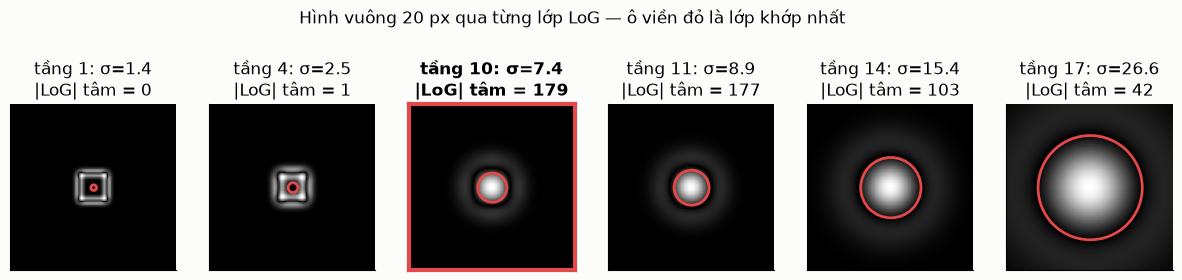

In [13]:
SIGMAS = h.scale_pyramid(sigma0=1.2, xi=1.2, n_levels=18)
print('Tháp σ:', np.round(SIGMAS, 1))

demo = make_square(20)
demo_vals = log_at_center(demo, SIGMAS)
best = int(np.argmax(demo_vals))

fig, axes = plt.subplots(1, 6, figsize=(15, 3.2))
for ax, n in zip(axes, [1, 4, best, 11, 14, 17]):
    ax.imshow(h.log_normalized(demo, SIGMAS[n])[C - 60:C + 60, C - 60:C + 60], cmap='gray')
    ax.add_patch(plt.Circle((60, 60), SIGMAS[n] * np.sqrt(2), fill=False, color='#e34948', lw=2))
    ax.set_title(f'tầng {n}: σ={SIGMAS[n]:.1f}\n|LoG| tâm = {demo_vals[n]:.0f}',
                 fontweight='bold' if n == best else 'normal')
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if n == best:
        for s in ax.spines.values():
            s.set_visible(True); s.set_color('#e34948'); s.set_linewidth(3)
fig.suptitle('Hình vuông 20 px qua từng lớp LoG — ô viền đỏ là lớp khớp nhất', y=1.05)
plt.show()


**Đọc hình:** tầng 1–4 chỉ thấy viền, tâm ≈ 0. Tầng viền đỏ có vòng ôm vừa hình vuông nên đốm sáng nhất. Các tầng sau thì vật nhoè dần.

## 2. Mỗi vật có một "đỉnh" theo σ

Giờ đi **dọc** theo các lớp tại tâm vật, với 4 kích thước khác nhau. Đây chính là **bước 2 của Harris-Laplace**: giữ điểm ở lớp mà |LoG| lớn hơn hai lớp kề (`log_stack[s-1]`, `log_stack[s+1]` trong code của bạn).


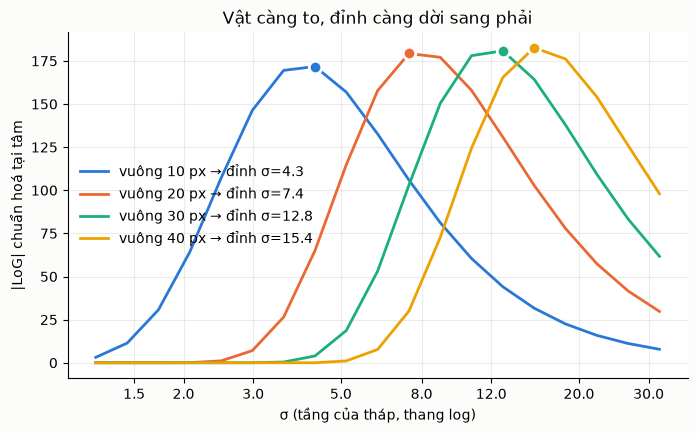

In [14]:
SIZES = [10, 20, 30, 40]
best_sigma = []

fig, ax = plt.subplots(figsize=(8, 4.5))
for side, color in zip(SIZES, COLORS):
    vals = log_at_center(make_square(side), SIGMAS)
    b = int(np.argmax(vals))
    best_sigma.append(SIGMAS[b])
    ax.plot(SIGMAS, vals, color=color, lw=2, label=f'vuông {side} px → đỉnh σ={SIGMAS[b]:.1f}')
    ax.plot(SIGMAS[b], vals[b], 'o', ms=9, color=color, mec='#fcfcfb', mew=2)
ax.set_xscale('log'); ax.set_xticks([1.5, 2, 3, 5, 8, 12, 20, 30])
ax.xaxis.set_major_formatter(plt.ScalarFormatter()); ax.minorticks_off()
ax.set_xlabel('σ (tầng của tháp, thang log)'); ax.set_ylabel('|LoG| chuẩn hoá tại tâm')
ax.set_title('Vật càng to, đỉnh càng dời sang phải'); ax.legend(frameon=False)
plt.show()


## 3. Kích thước vật ↔ σ được chọn: một đường thẳng

Đây là **ý nghĩa thực sự** của Harris-Laplace: nó tự đo kích thước của từng vật. Vật to gấp k lần thì σ được chọn cũng gấp k lần.

Vì vậy phóng ảnh không làm mất điểm. Vật to ra, đỉnh dời sang σ lớn hơn, và thuật toán **đi theo đỉnh**. Harris cổ điển đứng yên ở một σ cố định nên vật to ra là trượt: cùng cái khung, góc to trông giống một **cạnh thẳng**.


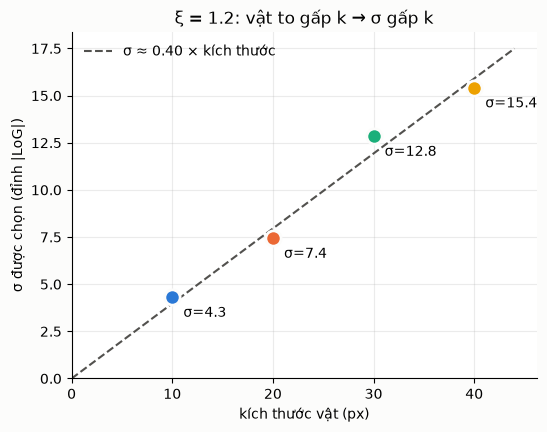

np.float64(0.3976854153619044)

In [15]:
def plot_size_vs_sigma(sizes, best_sigma, title):
    """Chấm (kích thước, σ đỉnh) và đường thẳng qua gốc σ = a·kích thước (bình phương tối thiểu)."""
    sizes, best_sigma = np.array(sizes), np.array(best_sigma)
    a = np.sum(sizes * best_sigma) / np.sum(sizes ** 2)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    xs = np.linspace(0, sizes.max() * 1.1, 10)
    ax.plot(xs, a * xs, '--', color='#52514e', lw=1.5, label=f'σ ≈ {a:.2f} × kích thước')
    for side, sig, color in zip(sizes, best_sigma, COLORS):
        ax.plot(side, sig, 'o', ms=11, color=color, mec='#fcfcfb', mew=2)
        ax.annotate(f'σ={sig:.1f}', (side, sig), textcoords='offset points', xytext=(8, -14))
    ax.set_xlim(0, None); ax.set_ylim(0, None)
    ax.set_xlabel('kích thước vật (px)'); ax.set_ylabel('σ được chọn (đỉnh |LoG|)')
    ax.set_title(title); ax.legend(frameon=False, loc='upper left')
    plt.show()
    return a

plot_size_vs_sigma(SIZES, best_sigma, 'ξ = 1.2: vật to gấp k → σ gấp k')


## 4. Tháp rời rạc: vì sao ξ quan trọng

Các chấm ở trên **không nằm đúng** trên đường thẳng, vì σ chỉ được chọn trong các tầng **có sẵn**. Với ξ = 1.2, hai tầng liền nhau cách nhau 20%, nên σ thật bị **làm tròn** về tầng gần nhất.

- **ξ lớn** (tầng thưa): làm tròn mạnh, chấm lệch xa đường thẳng, tỉ lệ đo được kém chính xác.
- **ξ nhỏ** (tầng dày): sát đường thẳng hơn, nhưng nhiều tầng hơn nên chạy lâu hơn.

Đây là cơ chế đằng sau câu hỏi "ξ, repeatability bão hoà ở đâu" trong đề. **Đoán trước khi chạy:** với ξ = 2.0, 4 chấm còn nằm trên đường không?


ξ=1.2: 19 tầng, σ đỉnh = [ 4.3  7.4 12.8 15.4]


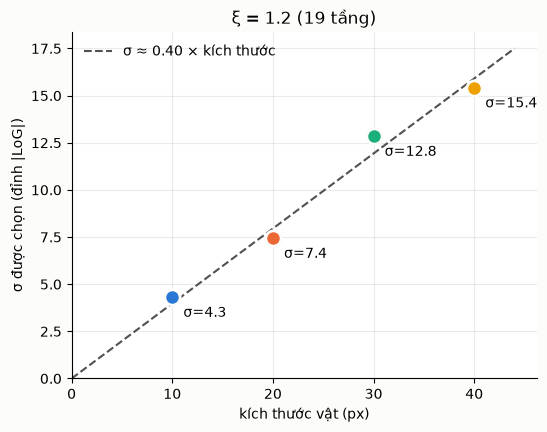

ξ=2.0: 6 tầng, σ đỉnh = [ 4.8  9.6  9.6 19.2]


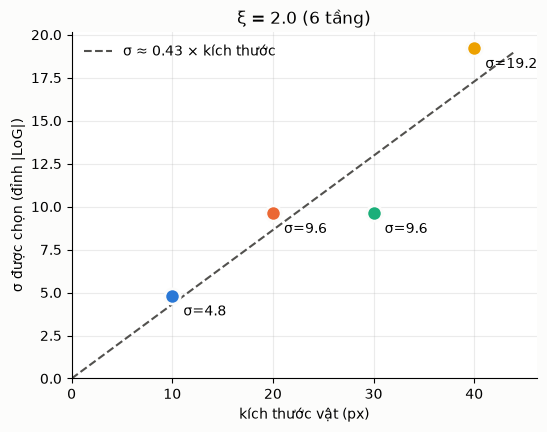

In [16]:
for xi in [1.2, 2.0]:
    n_levels = int(np.ceil(np.log(30 / 1.2) / np.log(xi)))      # luôn phủ σ từ 1.2 tới ~30
    sig = h.scale_pyramid(1.2, xi, n_levels)
    bs = [sig[int(np.argmax(log_at_center(make_square(s), sig)))] for s in SIZES]
    print(f'ξ={xi}: {len(sig)} tầng, σ đỉnh = {np.round(bs, 1)}')
    plot_size_vs_sigma(SIZES, bs, f'ξ = {xi} ({len(sig)} tầng)')


## 5. Thí nghiệm thật: ảnh nhỏ vs ảnh phóng to

Ghép mọi thứ lại:

1. Ảnh **A** = ảnh gốc thu nhỏ; ảnh **B** = A phóng to `SCALE` lần.
2. Chạy detector trên cả hai.
3. Nhân toạ độ điểm của A với `SCALE` để ra vị trí điểm đó trong B, đếm tỉ lệ có điểm của B nằm trong 3 px. Đó là `repeatability`.

**Công bằng:** Harris-Laplace thường trả về nhiều điểm hơn hẳn. Điểm dày thì "trúng" nhiều do ngẫu nhiên, nên ở đây cả hai detector đều chỉ giữ **N điểm mạnh nhất**.

**Chọn ảnh:** `chess.jpg` có góc sắc, ở tỉ lệ nào cũng là góc, nên khác biệt nhỏ. `flowers.jpg` có cấu trúc mềm, mỗi chỗ chỉ là góc ở **một** cỡ σ, nên khác biệt phải lớn.


In [17]:
SIZE_A, N_KEEP, XI = 120, 100, 1.4
SCALES = [1.0, 1.5, 2.0, 2.5, 3.0]
# dải ×8 trong A, nhân thêm hệ số phóng lớn nhất; +1 vì tầng cuối bị bỏ (thiếu hàng xóm)
SIGMAS_HL = h.scale_pyramid(1.2, XI, int(np.ceil(np.log(8 * max(SCALES)) / np.log(XI))) + 1)


def top_n_by_response(points, n):
    """Giữ n điểm có response (cột cuối) lớn nhất."""
    return points[np.argsort(-points[:, -1])][:n]


def repeat_after_scaling(grey, scale):
    """Repeatability (classic, Harris-Laplace) khi ảnh bị phóng `scale` lần."""
    a = cv.resize(grey, (SIZE_A, SIZE_A), interpolation=cv.INTER_AREA)
    b = cv.resize(a, None, fx=scale, fy=scale, interpolation=cv.INTER_CUBIC)
    t = 0.5 * (scale - 1)                                        # cv.resize căn theo tâm pixel
    S = np.array([[scale, 0, t], [0, scale, t]])                 # A (x, y) -> B (x, y)
    rep_classic = h.repeatability(top_n_by_response(h.harris_classic(a), N_KEEP),
                                  top_n_by_response(h.harris_classic(b), N_KEEP), S, b.shape)
    rep_hl = h.repeatability(top_n_by_response(h.harris_laplace(a, SIGMAS_HL), N_KEEP),
                             top_n_by_response(h.harris_laplace(b, SIGMAS_HL), N_KEEP), S, b.shape)
    return rep_classic, rep_hl


results = {}
for name in ['chess.jpg', 'flowers.jpg']:
    grey = h.convert2grey(cv.imread(name))
    results[name] = np.array([repeat_after_scaling(grey, s) for s in SCALES])
    print(name); print('  scale   classic   Harris-Laplace')
    for s, (rc, rh) in zip(SCALES, results[name]):
        print(f'  {s:4.1f}    {rc:6.3f}    {rh:6.3f}')

chess.jpg
  scale   classic   Harris-Laplace
   1.0     1.000     1.000
   1.5     0.860     0.810
   2.0     0.750     0.820
   2.5     0.520     0.760
   3.0     0.360     0.530
flowers.jpg
  scale   classic   Harris-Laplace
   1.0     1.000     1.000
   1.5     0.510     0.640
   2.0     0.280     0.540
   2.5     0.110     0.410
   3.0     0.080     0.360


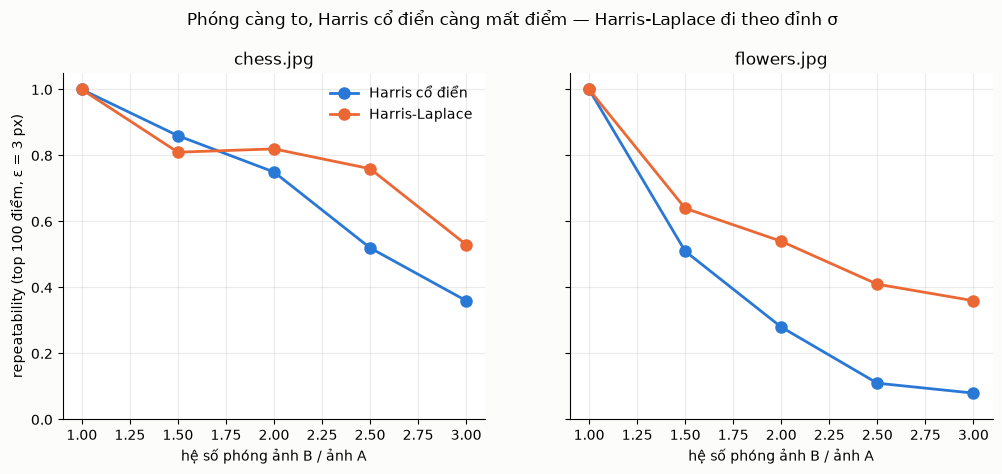

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    ax.plot(SCALES, r[:, 0], 'o-', color=COLORS[0], lw=2, ms=8, label='Harris cổ điển')
    ax.plot(SCALES, r[:, 1], 'o-', color=COLORS[1], lw=2, ms=8, label='Harris-Laplace')
    ax.set_title(name); ax.set_xlabel('hệ số phóng ảnh B / ảnh A'); ax.set_ylim(0, 1.05)
axes[0].set_ylabel(f'repeatability (top {N_KEEP} điểm, ε = 3 px)')
axes[0].legend(frameon=False)
fig.suptitle('Phóng càng to, Harris cổ điển càng mất điểm — Harris-Laplace đi theo đỉnh σ', y=1.02)
plt.show()


## Tóm tắt: trả lời 3 câu "giải thích thay đổi" của đề

| Câu hỏi | Trả lời |
|---|---|
| **Đại lượng nào** được tính khác đi? | σ dùng để tính R cho từng điểm. Harris cổ điển: một σ cố định cho cả ảnh. Harris-Laplace: mỗi điểm có σ riêng = lớp có \|LoG\| cực đại. |
| **Ở bước nào?** | Bước 2: so \|LoG\| với hai lớp kề theo trục tỉ lệ, chỉ giữ điểm ở lớp đỉnh. |
| **Vì sao dẫn tới hiện tượng?** | Phóng ảnh k lần thì đỉnh \|LoG\| dời sang σ gấp k lần (mục 3). Harris-Laplace đi theo đỉnh nên "kính lúp" luôn vừa khít với góc. Harris cổ điển giữ kính cũ: góc to ra trông như cạnh thẳng nên R nhỏ, điểm bị loại. |

**Thử tiếp:** đổi `XI` (1.1 → 2.0) ở mục 5 và xem đường cam thay đổi thế nào. Liên hệ với mục 4 (làm tròn σ).

**Giới hạn của notebook này:** mục 1–4 đo LoG ở **tâm** hình vuông (blob), không phải ở góc. Quy luật "to k lần thì σ gấp k lần" vẫn đúng ở góc, nhưng hệ số 0.4 sẽ khác.


chess.jpg
  góc    classic   Harris-Laplace
    0°     1.000     1.000
   15°     0.940     0.950
   30°     0.938     0.946
   45°     0.927     0.902
   60°     0.927     0.957
   75°     0.980     0.940
   90°     1.000     1.000
flowers.jpg
  góc    classic   Harris-Laplace
    0°     0.920     0.910
   15°     0.943     0.928
   30°     0.919     0.939
   45°     0.894     0.835
   60°     0.895     0.875
   75°     0.902     0.848
   90°     0.920     0.910


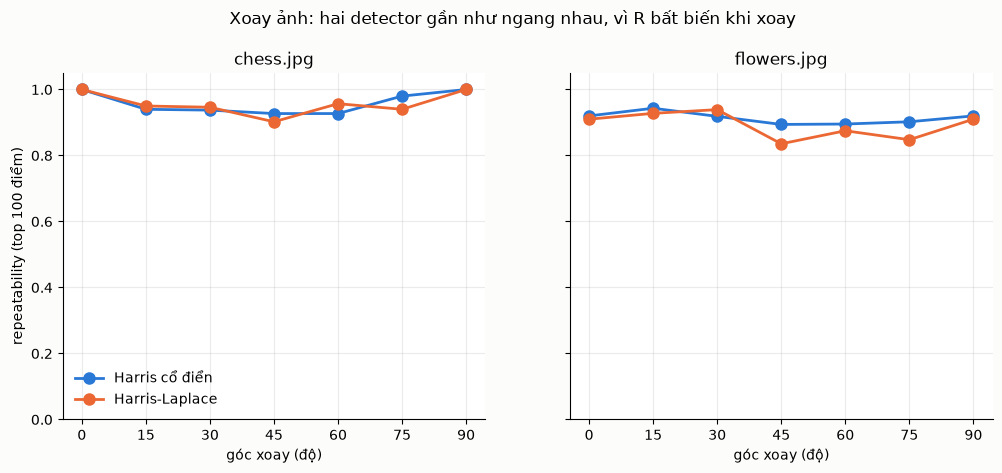

In [19]:
ANGLES = [0, 15, 30, 45, 60, 75, 90]
SIZE_ROT = 240   # lớn hơn SIZE_A để nội suy khi xoay ít làm méo góc


def drop_points_from_black_corners(points, M_inv, shape_a, margin=5):
    """Bỏ điểm q của B nếu T⁻¹(q) = M_inv · [x, y, 1]ᵀ rơi ra ngoài A (vùng đen do xoay)."""
    xy1 = np.column_stack((points[:, 1], points[:, 0], np.ones(len(points))))   # (row, col) -> (x, y, 1)
    x, y = (xy1 @ M_inv.T).T
    H, W = shape_a
    keep = (x >= margin) & (x < W - margin) & (y >= margin) & (y < H - margin)
    return points[keep]


def repeat_after_rotation(grey, angle):
    """Repeatability (classic, Harris-Laplace) khi ảnh bị xoay `angle` độ quanh tâm."""
    a = cv.resize(grey, (SIZE_ROT, SIZE_ROT), interpolation=cv.INTER_AREA)
    center = ((SIZE_ROT - 1) / 2, (SIZE_ROT - 1) / 2)          # tâm pixel thật -> 90° là hoán vị chính xác
    M = cv.getRotationMatrix2D(center, angle, 1.0)             # A (x, y) -> B (x, y)
    b = cv.warpAffine(a, M, (SIZE_ROT, SIZE_ROT), flags=cv.INTER_CUBIC)
    M_inv = cv.invertAffineTransform(M)

    reps = []
    for detect in (h.harris_classic, lambda img: h.harris_laplace(img, SIGMAS_HL)):
        pts_a = top_n_by_response(detect(a), N_KEEP)
        pts_b = top_n_by_response(drop_points_from_black_corners(detect(b), M_inv, a.shape), N_KEEP)
        reps.append(h.repeatability(pts_a, pts_b, M, b.shape))
    return reps


rot_results = {}
for name in ['chess.jpg', 'flowers.jpg']:
    grey = h.convert2grey(cv.imread(name))
    rot_results[name] = np.array([repeat_after_rotation(grey, ang) for ang in ANGLES])
    print(name); print('  góc    classic   Harris-Laplace')
    for ang, (rc, rh) in zip(ANGLES, rot_results[name]):
        print(f'  {ang:3d}°    {rc:6.3f}    {rh:6.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, r) in zip(axes, rot_results.items()):
    ax.plot(ANGLES, r[:, 0], 'o-', color=COLORS[0], lw=2, ms=8, label='Harris cổ điển')
    ax.plot(ANGLES, r[:, 1], 'o-', color=COLORS[1], lw=2, ms=8, label='Harris-Laplace')
    ax.set_title(name); ax.set_xlabel('góc xoay (độ)'); ax.set_ylim(0, 1.05); ax.set_xticks(ANGLES)
axes[0].set_ylabel(f'repeatability (top {N_KEEP} điểm)')
axes[0].legend(frameon=False)
fig.suptitle('Xoay ảnh: hai detector gần như ngang nhau, vì R bất biến khi xoay', y=1.02)
plt.show()

rep(không biến dạng) = [np.float64(1.0), np.float64(1.0)]
chess.jpg    0°, f=1.0    classic=[1.   0.69 0.61 0.58 0.28]  HL=[1.   0.88 0.73 0.17 0.14]
chess.jpg    30°, f=1.0   classic=[0.94 0.78 0.61 0.53 0.17]  HL=[0.95 0.89 0.68 0.19 0.13]
chess.jpg    30°, f=0.5   classic=[0.99 0.71 0.47 0.42 0.37]  HL=[0.88 0.7  0.39 0.26 0.16]
flowers.jpg  0°, f=1.0    classic=[1.   0.88 0.57 0.34 0.17]  HL=[1.   0.59 0.3  0.16 0.15]
flowers.jpg  30°, f=1.0   classic=[0.96 0.92 0.64 0.33 0.17]  HL=[0.95 0.66 0.28 0.16 0.15]
flowers.jpg  30°, f=0.5   classic=[0.49 0.37 0.28 0.15 0.12]  HL=[0.69 0.5  0.29 0.09 0.06]


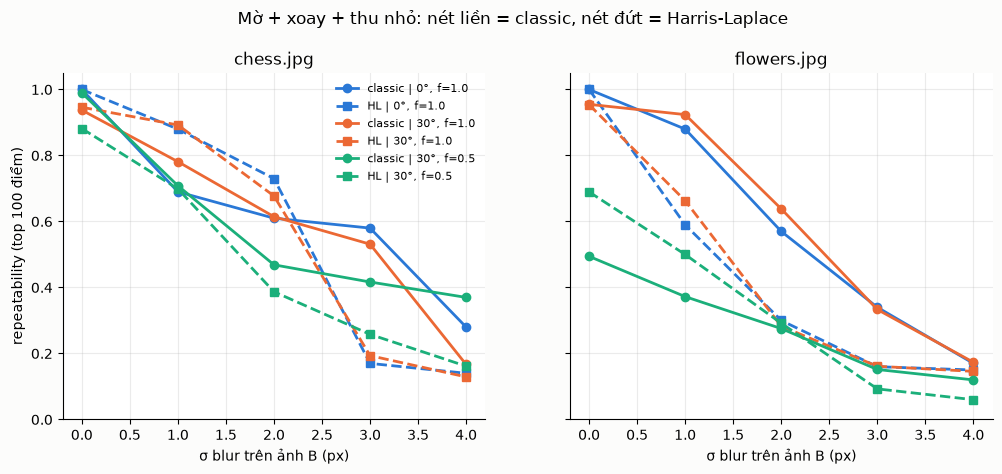

In [20]:
BLURS = [0, 1, 2, 3, 4]                         # σ của Gauss blur trên ảnh B (px)
CONDITIONS = [(0, 1.0), (30, 1.0), (30, 0.5)]   # (góc xoay, hệ số thu nhỏ f)
IDENTITY = np.array([[1.0, 0, 0], [0, 1, 0]])


def distort(a, angle, scale, blur_sigma):
    """B = blur(xoay(thu nhỏ(A))). -> (B, M) với M = R · S: A (x, y) -> B (x, y).
    S: x' = f·x + 0.5(f − 1)  (khớp cv.resize căn theo tâm pixel)
    """
    small = cv.resize(a, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)
    H, W = small.shape
    R = cv.getRotationMatrix2D(((W - 1) / 2, (H - 1) / 2), angle, 1.0)
    b = cv.warpAffine(small, R, (W, H), flags=cv.INTER_CUBIC)
    if blur_sigma > 0:
        b = cv.GaussianBlur(b, (0, 0), blur_sigma)   # mờ không dời điểm -> M giữ nguyên
    t = 0.5 * (scale - 1)
    S = np.array([[scale, 0, t], [0, scale, t], [0, 0, 1]])
    return b, R @ S


def repeat_after_distortion(grey, angle, scale, blur_sigma):
    """Repeatability (classic, Harris-Laplace) khi A bị thu nhỏ, xoay rồi làm mờ."""
    a = cv.resize(grey, (SIZE_ROT, SIZE_ROT), interpolation=cv.INTER_AREA)
    b, M = distort(a, angle, scale, blur_sigma)
    M_inv = cv.invertAffineTransform(M)
    margin = int(5 + 3 * blur_sigma / scale)   # mép đen bị mờ lan vào ~3σ px của B, quy về toạ độ A

    reps = []
    for detect in (h.harris_classic, lambda img: h.harris_laplace(img, SIGMAS_HL)):
        # bỏ điểm sát mép ở CẢ A lẫn B để hai bên công bằng
        pts_a = top_n_by_response(drop_points_from_black_corners(detect(a), IDENTITY, a.shape, margin), N_KEEP)
        pts_b = top_n_by_response(drop_points_from_black_corners(detect(b), M_inv, a.shape, margin), N_KEEP)
        reps.append(h.repeatability(pts_a, pts_b, M, b.shape))
    return reps


# Tự kiểm tra: không biến dạng gì thì phải ra 1.0
print('rep(không biến dạng) =', repeat_after_distortion(h.convert2grey(cv.imread('chess.jpg')), 0, 1.0, 0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, name in zip(axes, ['chess.jpg', 'flowers.jpg']):
    grey = h.convert2grey(cv.imread(name))
    for (angle, scale), color in zip(CONDITIONS, COLORS):
        r = np.array([repeat_after_distortion(grey, angle, scale, s) for s in BLURS])
        label = f'{angle}°, f={scale}'
        ax.plot(BLURS, r[:, 0], 'o-', color=color, lw=2, label=f'classic | {label}')
        ax.plot(BLURS, r[:, 1], 's--', color=color, lw=2, label=f'HL | {label}')
        print(f'{name:12} {label:12} classic={np.round(r[:, 0], 2)}  HL={np.round(r[:, 1], 2)}')
    ax.set_title(name); ax.set_xlabel('σ blur trên ảnh B (px)'); ax.set_ylim(0, 1.05)
axes[0].set_ylabel(f'repeatability (top {N_KEEP} điểm)')
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Mờ + xoay + thu nhỏ: nét liền = classic, nét đứt = Harris-Laplace', y=1.02)
plt.show()

In [21]:
from scipy.spatial import cKDTree

def diagnose_hl_scaling(grey, scale, eps_a=1.5):
    """Rep HL theo 3 cách đo + trung vị σ_B/σ_A của cặp khớp (lý tưởng = scale)."""
    a = cv.resize(grey, (SIZE_A, SIZE_A), interpolation=cv.INTER_AREA)
    b = cv.resize(a, None, fx=scale, fy=scale, interpolation=cv.INTER_CUBIC)
    t = 0.5 * (scale - 1)
    S_old = np.array([[scale, 0, 0], [0, scale, 0]])
    S_new = np.array([[scale, 0, t], [0, scale, t]])
    pa = top_n_by_response(h.harris_laplace(a, SIGMAS_HL), N_KEEP)
    pb = top_n_by_response(h.harris_laplace(b, SIGMAS_HL), N_KEEP)
    reps = (h.repeatability(pa, pb, S_old, b.shape),                       # S cũ, eps = 3
            h.repeatability(pa, pb, S_new, b.shape),                       # S đúng, eps = 3
            h.repeatability(pa, pb, S_new, b.shape, eps=eps_a * scale))    # S đúng, eps theo toạ độ A
    dist, idx = cKDTree(pb[:, :2]).query(pa[:, :2] * scale + t)            # (row, col) cũng dùng chung s, t
    ok = dist <= eps_a * scale
    sigma_ratio = np.median(pb[idx[ok], 2] / pa[ok, 2]) if ok.any() else np.nan
    return reps, sigma_ratio

grey = h.convert2grey(cv.imread('flowers.jpg'))
print('scale | S cũ  | S đúng | +eps theo A | σ_B/σ_A')
for s in SCALES:
    (r0, r1, r2), ratio = diagnose_hl_scaling(grey, s)
    print(f'{s:5.1f} | {r0:.2f}  | {r1:.2f}   | {r2:.2f}        | {ratio:.2f}')

scale | S cũ  | S đúng | +eps theo A | σ_B/σ_A
  1.0 | 1.00  | 1.00   | 1.00        | 1.00
  1.5 | 0.63  | 0.64   | 0.60        | 1.40
  2.0 | 0.55  | 0.54   | 0.54        | 1.40
  2.5 | 0.41  | 0.41   | 0.43        | 1.96
  3.0 | 0.35  | 0.36   | 0.40        | 2.74


chess.jpg    cv Harris (GFTT)   [1.   0.8  0.8  0.16 0.  ]
chess.jpg    cv SIFT (DoG)      [1.   0.96 0.93 0.94 1.  ]
flowers.jpg  cv Harris (GFTT)   [1.   0.58 0.39 0.14 0.12]
flowers.jpg  cv SIFT (DoG)      [1.   0.26 0.14 0.17 0.2 ]


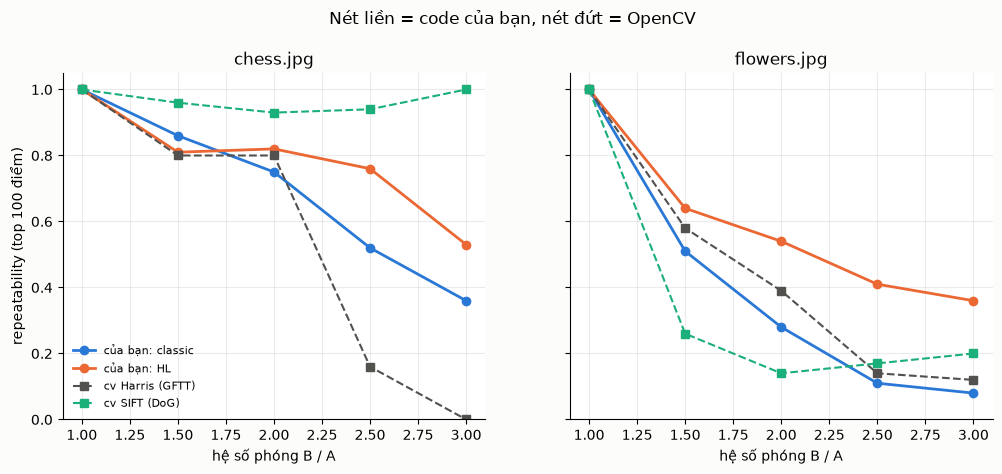

In [24]:
def keypoints_to_array(kps):
    """KeyPoint của OpenCV -> (N, 4): (row, col, sigma ≈ size/2, response). pt là (x, y) nên phải đảo."""
    return np.array([(k.pt[1], k.pt[0], k.size / 2, k.response) for k in kps]).reshape(-1, 4)


def repeat_after_scaling_cv(grey, scale, detector):
    """Giống repeat_after_scaling (Cell 12), nhưng dùng một detector của OpenCV."""
    a = cv.resize(grey, (SIZE_A, SIZE_A), interpolation=cv.INTER_AREA)
    b = cv.resize(a, None, fx=scale, fy=scale, interpolation=cv.INTER_CUBIC)
    t = 0.5 * (scale - 1)
    S = np.array([[scale, 0, t], [0, scale, t]])
    # detector của OpenCV cần ảnh uint8; INTER_CUBIC có thể vượt ra ngoài [0, 255] nên phải clip
    detect = lambda img: keypoints_to_array(detector.detect(np.clip(img, 0, 255).astype(np.uint8)))
    return h.repeatability(top_n_by_response(detect(a), N_KEEP),
                           top_n_by_response(detect(b), N_KEEP), S, b.shape)


CV_DETECTORS = {
    'cv Harris (GFTT)': cv.GFTTDetector_create(maxCorners=N_KEEP, qualityLevel=0.01, minDistance=3,
                                               blockSize=5, useHarrisDetector=True, k=0.04),
    'cv SIFT (DoG)': cv.SIFT_create(),
}
if hasattr(cv, 'xfeatures2d'):   # chỉ có khi cài opencv-contrib-python
    CV_DETECTORS['cv Harris-Laplace'] = cv.xfeatures2d.HarrisLaplaceFeatureDetector_create()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, name in zip(axes, ['chess.jpg', 'flowers.jpg']):
    grey = h.convert2grey(cv.imread(name))
    ax.plot(SCALES, results[name][:, 0], 'o-', color=COLORS[0], lw=2, label='của bạn: classic')
    ax.plot(SCALES, results[name][:, 1], 'o-', color=COLORS[1], lw=2, label='của bạn: HL')
    for (label, det), color in zip(CV_DETECTORS.items(), ['#52514e', COLORS[2], COLORS[3]]):
        reps = [repeat_after_scaling_cv(grey, s, det) for s in SCALES]
        print(f'{name:12} {label:18} {np.round(reps, 2)}')   # giá trị ở scale 1.0 phải là 1.0
        ax.plot(SCALES, reps, 's--', color=color, lw=1.5, label=label)
    ax.set_title(name); ax.set_xlabel('hệ số phóng B / A'); ax.set_ylim(0, 1.05)
axes[0].set_ylabel(f'repeatability (top {N_KEEP} điểm)')
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Nét liền = code của bạn, nét đứt = OpenCV', y=1.02)
plt.show()